# Project 1: Bank Marketing — Term Deposit Subscription
**Course:** DSC8307 Data Mining, Modeling and Analytics  
**Objective:** predict subscription (`y`) before a marketing call, to support customer selection.

This notebook is designed to run from top to bottom. It uses a stratified train/validation/test split. The validation set supports model/threshold decisions; the test set is held back for final evaluation.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, precision_recall_curve)
RANDOM_STATE=42
DATA_PATH=os.path.join("data","bank-additional-full.csv")
df=pd.read_csv(DATA_PATH, sep=";")
print("Shape:", df.shape)
display(df.head())

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Data understanding and exploratory analysis
The data contains demographic, financial, contact-history and macroeconomic variables. `y` is the binary outcome. The source documentation identifies `unknown` categories as missing/undisclosed values, rather than conventional nulls.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nNull values: 0
\nTarget counts:


,count
outcome,
no,36548
yes,4640


,percent
y,
no,88.73
yes,11.27


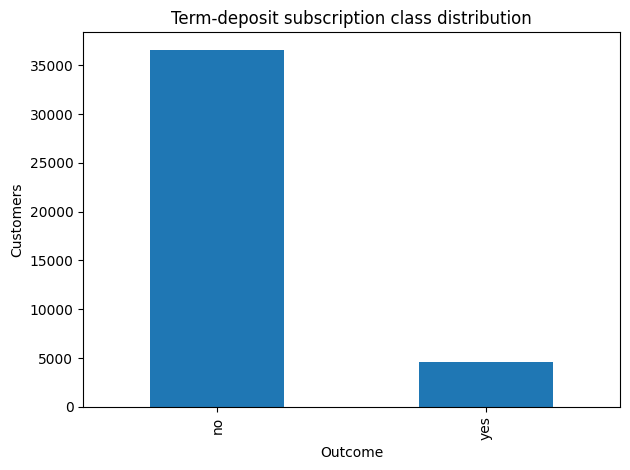

In [2]:
print(df.info())
display(df.describe(include="all").T)
print("\\nNull values:", int(df.isna().sum().sum()))
print("\\nTarget counts:")
display(df["y"].value_counts().rename_axis("outcome").to_frame("count"))
display((df["y"].value_counts(normalize=True)*100).round(2).rename("percent").to_frame())
df["y"].value_counts().reindex(["no","yes"]).plot(kind="bar")
plt.title("Term-deposit subscription class distribution"); plt.xlabel("Outcome"); plt.ylabel("Customers"); plt.tight_layout(); plt.show()

**Initial findings.** The dataset has 41,188 observations and 21 columns including the target. The target is imbalanced: approximately 88.7% `no` and 11.3% `yes`. A model that always predicts `no` therefore has high accuracy but zero ability to identify subscribers. The supplied file has no blank/null cells; `unknown` is retained as an explicit category because it may contain information about non-disclosure or data collection.

In [3]:
# Inspect category levels and special values
for c in df.select_dtypes(include="object").columns:
    print(f"{c}: {df[c].nunique()} levels; unknown={(df[c]=='unknown').sum() if c!='y' else 'target'}")
print("\\nNumeric correlations with target encoded as 1:")
num=df.select_dtypes(include=np.number).copy()
num["subscribed"]=(df["y"]=="yes").astype(int)
display(num.corr(numeric_only=True)["subscribed"].sort_values(ascending=False).to_frame("correlation"))

job: 12 levels; unknown=330
marital: 4 levels; unknown=80
education: 8 levels; unknown=1731
default: 3 levels; unknown=8597
housing: 3 levels; unknown=990
loan: 3 levels; unknown=990
contact: 2 levels; unknown=0
month: 10 levels; unknown=0
day_of_week: 5 levels; unknown=0
poutcome: 3 levels; unknown=0
y: 2 levels; unknown=target
\nNumeric correlations with target encoded as 1:


,correlation
subscribed,1.000000
duration,0.405274
previous,0.230181
cons.conf.idx,0.054878
age,0.030399
campaign,-0.066357
cons.price.idx,-0.136211
emp.var.rate,-0.298334
euribor3m,-0.307771
pdays,-0.324914


## 2. Data preparation and baseline
- Remove `duration` from operational features: it is only observed during/after the call, so it cannot support pre-call targeting.
- Keep `pdays=999` as the documented sentinel meaning the customer was not previously contacted; it is meaningful, not a missing value.
- Keep `unknown` category values as a level, as the data dictionary permits.
- Use one-hot encoding for categorical variables and median imputation/scaling for numeric variables (pipeline-safe even though no nulls were found).
- Stratify all splits to preserve the minority-class proportion.

The majority-class baseline predicts `no` for every customer. Accuracy is the majority share, but recall and F1 for subscribers are zero.

In [4]:
X=df.drop(columns=["y","duration"])
y=(df["y"]=="yes").astype(int)
X_train, X_temp, y_train, y_temp=train_test_split(X,y,test_size=0.30,random_state=RANDOM_STATE,stratify=y)
X_val, X_test, y_val, y_test=train_test_split(X_temp,y_temp,test_size=0.50,random_state=RANDOM_STATE,stratify=y_temp)
print("Split sizes:",len(X_train),len(X_val),len(X_test))
baseline=np.zeros(len(y_test),dtype=int)
baseline_metrics={"Accuracy":accuracy_score(y_test,baseline),
                  "Precision":precision_score(y_test,baseline,zero_division=0),
                  "Recall":recall_score(y_test,baseline,zero_division=0),
                  "F1":f1_score(y_test,baseline,zero_division=0)}
display(pd.Series(baseline_metrics,name="Majority baseline").to_frame())
numeric_features=X.select_dtypes(include=np.number).columns.tolist()
categorical_features=X.select_dtypes(exclude=np.number).columns.tolist()
preprocess=ColumnTransformer([
    ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())]),numeric_features),
    ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical_features)
])

Split sizes: 28831 6178 6179


,Majority baseline
Accuracy,0.88736
Precision,0.00000
Recall,0.00000
F1,0.00000


## 3. Model selection and ranking
Three suitable approaches are compared:
1. **Logistic regression (class-weighted):** interpretable linear baseline, efficient and often well-calibrated after suitable calibration.
2. **Random forest (class-weighted):** captures nonlinearities and interactions, with reduced reliance on a linear decision boundary.
3. **Histogram gradient boosting:** sequentially learns residual patterns and can model complex nonlinear effects efficiently.

Because identifying subscribers is the business objective and classes are imbalanced, average precision (area under the precision–recall curve) is the primary ranking metric; ROC-AUC, recall, precision and F1 provide supporting evidence. Models are ranked on validation data, not on the test set.

In [5]:
models={
 "Logistic regression":Pipeline([("prep",preprocess),("model",LogisticRegression(max_iter=1500,class_weight="balanced",C=1.0,random_state=RANDOM_STATE))]),
 "Random forest":Pipeline([("prep",preprocess),("model",RandomForestClassifier(n_estimators=250,min_samples_leaf=3,class_weight="balanced_subsample",n_jobs=-1,random_state=RANDOM_STATE))]),
 "HistGradientBoosting":Pipeline([("prep",preprocess),("model",HistGradientBoostingClassifier(max_iter=180,learning_rate=0.08,max_leaf_nodes=15,l2_regularization=1.0,random_state=RANDOM_STATE))])
}
fitted={}
rows=[]
for name,pipe in models.items():
    pipe.fit(X_train,y_train)
    fitted[name]=pipe
    p=pipe.predict_proba(X_val)[:,1]
    pred=(p>=0.5).astype(int)
    rows.append({"Model":name,"Average precision":average_precision_score(y_val,p),
                 "ROC-AUC":roc_auc_score(y_val,p),"Precision@0.5":precision_score(y_val,pred,zero_division=0),
                 "Recall@0.5":recall_score(y_val,pred),"F1@0.5":f1_score(y_val,pred)})
validation_results=pd.DataFrame(rows).sort_values("Average precision",ascending=False)
display(validation_results)
best_name=validation_results.iloc[0]["Model"]
best_model=fitted[best_name]
print("Validation-selected model:",best_name)

,Model,Average precision,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5
2,HistGradientBoosting,0.492839,0.812735,0.702929,0.241379,0.359358
1,Random forest,0.486134,0.800046,0.477995,0.561782,0.516513
0,Logistic regression,0.464771,0.802087,0.361564,0.637931,0.461538


Validation-selected model: HistGradientBoosting


## 4. Decision threshold and trade-off
A 0.5 cutoff is not automatically appropriate. A low threshold finds more potential subscribers (higher recall) but increases unnecessary calls (false positives). A high threshold reduces calls but misses more subscribers (false negatives).

For illustration, assume a missed subscriber is five times as costly as an unnecessary call: `cost = 5 × FN + 1 × FP`. This is a transparent planning assumption, not a measured Platinum/Portuguese bank cost. Choose the threshold on validation data that minimises this cost, then lock it before test evaluation.

,Selected validation operating point
threshold,0.140000
FP,605.000000
FN,252.000000
TP,444.000000
calls_selected,1049.000000
assumed_cost,1865.000000
precision,0.423260
recall,0.637931


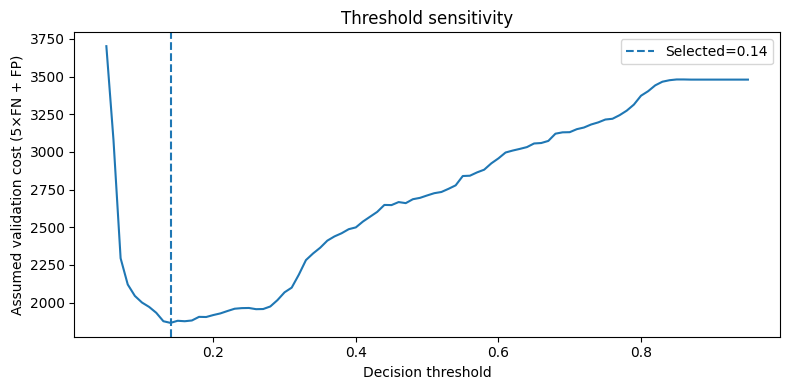

In [6]:
val_prob=best_model.predict_proba(X_val)[:,1]
thresholds=np.linspace(0.05,0.95,91)
cost_rows=[]
for t in thresholds:
    pr=(val_prob>=t).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_val,pr,labels=[0,1]).ravel()
    cost=5*fn+fp
    cost_rows.append({"threshold":t,"FP":fp,"FN":fn,"TP":tp,"calls_selected":int(pr.sum()),"assumed_cost":cost,
                      "precision":precision_score(y_val,pr,zero_division=0),"recall":recall_score(y_val,pr)})
threshold_table=pd.DataFrame(cost_rows)
best_row=threshold_table.loc[threshold_table.assumed_cost.idxmin()]
chosen_threshold=float(best_row.threshold)
display(best_row.to_frame("Selected validation operating point"))
plt.figure(figsize=(8,4))
plt.plot(threshold_table.threshold,threshold_table.assumed_cost)
plt.axvline(chosen_threshold,linestyle="--",label=f"Selected={chosen_threshold:.2f}")
plt.xlabel("Decision threshold"); plt.ylabel("Assumed validation cost (5×FN + FP)")
plt.title("Threshold sensitivity"); plt.legend(); plt.tight_layout(); plt.show()

## 5. Final test evaluation
The selected model and threshold are evaluated once on the held-out test set. The test set was not used to select the model or threshold.

,Test result
Selected model,HistGradientBoosting
Threshold,0.14
Accuracy,0.860819
Precision,0.422495
Recall,0.642241
F1,0.509692
ROC-AUC,0.814427
Average precision,0.492815
TN,4872
FP,611


              precision    recall  f1-score   support

          No       0.95      0.89      0.92      5483
         Yes       0.42      0.64      0.51       696

    accuracy                           0.86      6179
   macro avg       0.69      0.77      0.71      6179
weighted avg       0.89      0.86      0.87      6179



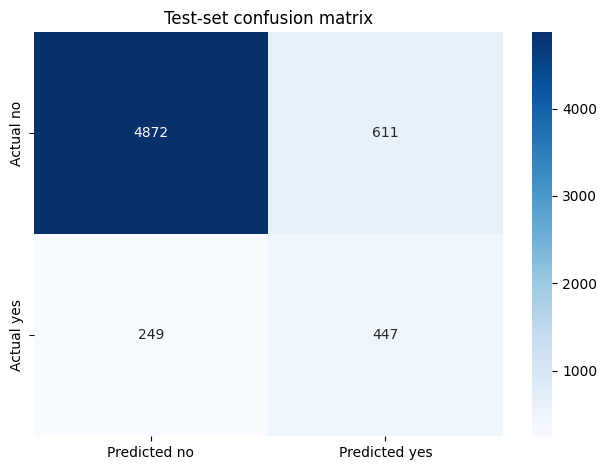

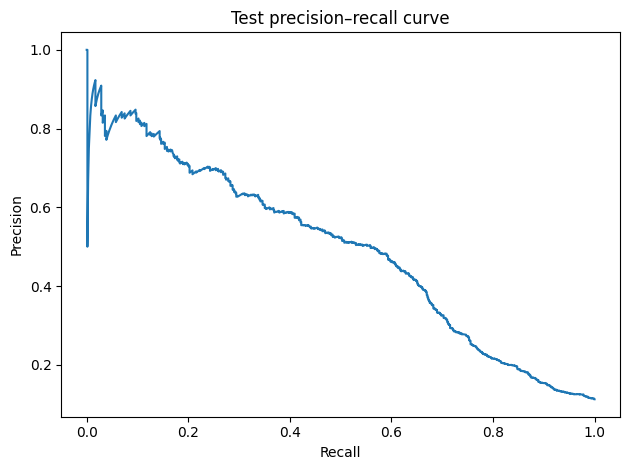

In [7]:
test_prob=best_model.predict_proba(X_test)[:,1]
test_pred=(test_prob>=chosen_threshold).astype(int)
tn,fp,fn,tp=confusion_matrix(y_test,test_pred,labels=[0,1]).ravel()
test_summary=pd.DataFrame([{
 "Selected model":best_name,"Threshold":chosen_threshold,
 "Accuracy":accuracy_score(y_test,test_pred),
 "Precision":precision_score(y_test,test_pred,zero_division=0),
 "Recall":recall_score(y_test,test_pred),
 "F1":f1_score(y_test,test_pred),
 "ROC-AUC":roc_auc_score(y_test,test_prob),
 "Average precision":average_precision_score(y_test,test_prob),
 "TN":tn,"FP":fp,"FN":fn,"TP":tp,
 "Assumed cost (5×FN+FP)":5*fn+fp
}])
display(test_summary.T.rename(columns={0:"Test result"}))
print(classification_report(y_test,test_pred,target_names=["No","Yes"],zero_division=0))
sns.heatmap([[tn,fp],[fn,tp]],annot=True,fmt="d",cmap="Blues",xticklabels=["Predicted no","Predicted yes"],yticklabels=["Actual no","Actual yes"])
plt.title("Test-set confusion matrix"); plt.tight_layout(); plt.show()
precision,recall,_=precision_recall_curve(y_test,test_prob)
plt.plot(recall,precision); plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Test precision–recall curve"); plt.tight_layout(); plt.show()

## 6. Interpretation, limitations and recommendation
Use the validation-ranked results and held-out test metrics above as the evidence for the final ranking. A practical campaign should use the chosen validation threshold only after the bank has replaced the illustrative 5:1 cost ratio with its own economics (call cost, expected deposit value, capacity and customer-contact rules). If call capacity is fixed, rank customers by predicted probability and contact the top-scoring customers instead of relying on a universal threshold.

Limitations include historical campaign bias, possible temporal drift, macroeconomic variables that may change, unknown-category ambiguity, and the fact that association does not establish that contacting a customer causes subscription. The split is random rather than time-based; a future deployment study should validate on a later campaign period. `duration` is deliberately excluded from operational prediction.